# TextCNN trên Google Colab

Thành viên 2: trình bày tokenizer regex, vocabulary chỉ từ train, PAD=0/UNK=1, padding/cắt 128 token, embedding, convolution 3/4/5 và max pooling. Chọn epoch theo dev macro-F1; GPU được khuyến nghị.

Chỉ train trên Colab. Sửa cấu hình, rồi **Runtime → Run all**. Lần đầu giữ SMOKE=True để kiểm tra luồng; sau đó dùng ID mới và SMOKE=False cho kết quả chính thức. Cả nhóm phải dùng cùng ZIP/SHA repo và cùng dữ liệu/cấu hình mapping/seed. Chưa có kết quả cho tới khi notebook chạy thành công. Nếu Colab yêu cầu restart sau pip, restart rồi Run all.


## 1. Cấu hình

Đã điền preset cho CSV của nhóm: free_text/label_id; 0=CLEAN, 1=OFFENSIVE, 2=HATE, đối chiếu notebook tác giả. SHA-256 cố định cùng snapshot; bỏ dòng văn bản rỗng có ghi metadata. Không cần đổi tên dev.csv. Không điền token tại đây: dùng Colab Secrets với tên HF_TOKEN. Với HF, xác nhận đường dẫn file từ Files của revision được cấp quyền.


In [8]:
# Điền giống nhau ở cả ba notebook trước khi Runtime → Run all.
SOURCE_MODE = "git"
REPO_URL = "https://github.com/thong312/NLP501_Vietnamese_Comment_Classification.git"
REPO_REVISION = "eeb1cd0a6c8929a3bd01eab0bde976b92e45751b"

DATA_MODE = "csv"
CSV_DIR = "/content/vihsd-data"
UPLOAD_CSV = True
HF_REVISION = ""  # SHA commit đầy đủ của uitnlp/vihsd nếu DATA_MODE="hf"
HF_FILENAMES = {"train": "train.csv", "dev": "dev.csv", "test": "test.csv"}
# Preset cho đúng ba CSV nhóm đã tải và kiểm tra; không chứa bình luận nguồn.
DATASET_CONFIG = {'source': 'https://huggingface.co/datasets/uitnlp/vihsd', 'text_column': 'free_text', 'label_column': 'label_id', 'label_mapping': {'0': 'CLEAN', '1': 'OFFENSIVE', '2': 'HATE'}, 'mapping_source': 'https://github.com/sonlam1102/vihsd/blob/main/ViHSD_DNN.ipynb — label_id được dùng trực tiếp với to_categorical; confusion_matrix theo thứ tự clean/offensive/hate; đối chiếu ngày 2026-11-10', 'empty_text_policy': 'drop', 'expected_sha256': {'train': '516a4ac12bcfd64720a6de352b3c30d019377f90a5907eff80e91d0ae2526360', 'dev': '1d42bc7e78b796f9a61bb30490171e5d48cbdee41f97c1235754894d28402ff7', 'test': 'ba8ae9b62c40caebcbe8af9a09590296bca286e83e22dd639de31a62ed16f5a5'}}
TEXT_COLUMN = DATASET_CONFIG["text_column"]
LABEL_COLUMN = DATASET_CONFIG["label_column"]
LABEL_MAPPING = DATASET_CONFIG["label_mapping"]
MAPPING_SOURCE = DATASET_CONFIG["mapping_source"]
CSV_SOURCE = DATASET_CONFIG["source"]
EMPTY_TEXT_POLICY = DATASET_CONFIG["empty_text_policy"]  # drop: ghi nhận và bỏ văn bản rỗng
EXPECTED_SHA256 = DATASET_CONFIG["expected_sha256"]  # cùng snapshot cho cả ba notebook
SEED = 42
SMOKE = False  # đổi False cho lần train chính thức; smoke không được chọn model
RUN_ID = "textcnn-full-025-001"  # dùng ID mới cho mỗi lần chạy; không ghi đè artifact
PHOBERT_REVISION = ""  # SHA commit đầy đủ vinai/phobert-base-v2, chỉ notebook 03 cần
EPOCHS = 25  # mặc định smoke=1; full TextCNN=5, PhoBERT=3
BATCH_SIZE = None  # TextCNN=64, PhoBERT=8; giảm còn 4/2 nếu hết VRAM
DOWNLOAD_ZIP = True
SAVE_TO_DRIVE = False
DRIVE_OUTPUT = "/content/drive/MyDrive/ViHSD"


## 2. Lấy source có dấu vết và cài môi trường

ZIP chỉ chứa source của nhóm; chia sẻ cùng một ZIP cho ba thành viên. Nếu clone Git, dùng URL repo nhóm đã đưa source lên và SHA commit đầy đủ.


In [2]:
import os, sys, subprocess, pathlib, hashlib, zipfile, shutil, re
try:
    from google.colab import files
except ImportError:
    raise RuntimeError("Notebook này chỉ train trên Google Colab.") from None
workspace = pathlib.Path("/content/vihsd-project")
if SOURCE_MODE == "git":
    if not REPO_URL or not re.fullmatch(r"[a-fA-F0-9]{40}", REPO_REVISION):
        raise ValueError("Điền REPO_URL và REPO_REVISION là SHA commit 40 ký tự.")
    if not workspace.exists():
        subprocess.run(["git", "clone", REPO_URL, str(workspace)], check=True)
    subprocess.run(["git", "-C", str(workspace), "checkout", "--detach", REPO_REVISION], check=True)
    actual_sha = subprocess.check_output(["git", "-C", str(workspace), "rev-parse", "HEAD"], text=True).strip()
    if actual_sha.lower() != REPO_REVISION.lower():
        raise ValueError("SHA repo không khớp.")
    CODE_PROVENANCE = {"mode": "git", "revision": actual_sha}
elif SOURCE_MODE == "zip":
    print("Upload ZIP mã nguồn của nhóm (không chứa dataset, token hay artifact).")
    uploaded = files.upload()
    if len(uploaded) != 1 or not next(iter(uploaded)).lower().endswith(".zip"):
        raise ValueError("Cần đúng một ZIP repo.")
    name, payload = next(iter(uploaded.items()))
    CODE_PROVENANCE = {"mode": "zip", "sha256": hashlib.sha256(payload).hexdigest()}
    archive_path = pathlib.Path("/content") / pathlib.Path(name).name
    archive_path.write_bytes(payload)
    # Fresh source folder for every upload; reject paths escaping its root.
    import tempfile
    unpack = pathlib.Path(tempfile.mkdtemp(prefix="vihsd-source-", dir="/content"))
    with zipfile.ZipFile(archive_path) as archive:
        for member in archive.infolist():
            if not (unpack / member.filename).resolve().is_relative_to(unpack.resolve()):
                raise ValueError("ZIP chứa đường dẫn không hợp lệ.")
        archive.extractall(unpack)
    candidates = [p.parent for p in unpack.rglob("pyproject.toml") if (p.parent / "src/vihsd").is_dir()]
    if len(candidates) != 1:
        raise ValueError("ZIP phải chứa đúng một root dự án có pyproject.toml và src/vihsd.")
    workspace = candidates[0]
else:
    raise ValueError("SOURCE_MODE chỉ nhận zip hoặc git.")
os.chdir(workspace)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation", "-e", "."], check=True)
# sys.path also supports editable install in the already-running notebook interpreter.
sys.path.insert(0, str(workspace / "src"))
import torch
print("Python:", sys.version.split()[0], "| PyTorch:", torch.__version__)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "CPU")
print("Nguồn code:", CODE_PROVENANCE)


Python: 3.13.16 | PyTorch: 2.7.1+cu126
GPU: Tesla T4
Nguồn code: {'mode': 'git', 'revision': 'eeb1cd0a6c8929a3bd01eab0bde976b92e45751b'}


## 3. Dữ liệu và phân bố nhãn

Dùng split gốc, giữ nguyên dòng trùng và báo số lượng. Bỏ văn bản rỗng theo preset chung, ghi số lượng và vị trí bản ghi (header tính là bản ghi 1); dừng nếu SHA khác, nhãn lạ, toàn bộ split rỗng hoặc thiếu lớp sau lọc. Không thay dataset.


Upload đồng thời train.csv, dev.csv và test.csv đã được cấp hợp lệ.


Saving dev.csv to dev.csv
Saving test.csv to test.csv
Saving train.csv to train.csv
Phân bố nhãn gốc: {'train': {'CLEAN': 19886, 'OFFENSIVE': 1606, 'HATE': 2556}, 'dev': {'CLEAN': 2190, 'OFFENSIVE': 212, 'HATE': 270}, 'test': {'CLEAN': 5548, 'OFFENSIVE': 444, 'HATE': 688}}
Bỏ văn bản rỗng theo quy tắc chung: {'train': {'count': 2, 'record_numbers': [10952, 20882]}, 'dev': {'count': 0, 'record_numbers': []}, 'test': {'count': 0, 'record_numbers': []}}
Phân bố sau lọc: {'train': {'CLEAN': 19885, 'OFFENSIVE': 1605, 'HATE': 2556}, 'dev': {'CLEAN': 2190, 'OFFENSIVE': 212, 'HATE': 270}, 'test': {'CLEAN': 5548, 'OFFENSIVE': 444, 'HATE': 688}}
Số mẫu dùng: {'train': {'CLEAN': 19885, 'OFFENSIVE': 1605, 'HATE': 2556}, 'dev': {'CLEAN': 2190, 'OFFENSIVE': 212, 'HATE': 270}, 'test': {'CLEAN': 5548, 'OFFENSIVE': 444, 'HATE': 688}}
Trùng giữa split (giữ nguyên split gốc, không in bình luận): {'train:dev': {'unique_texts': 321, 'rows': {'train': 351, 'dev': 324}}, 'train:test': {'unique_texts': 787, '

<Axes: title={'center': 'Phân bố nhãn theo split'}>

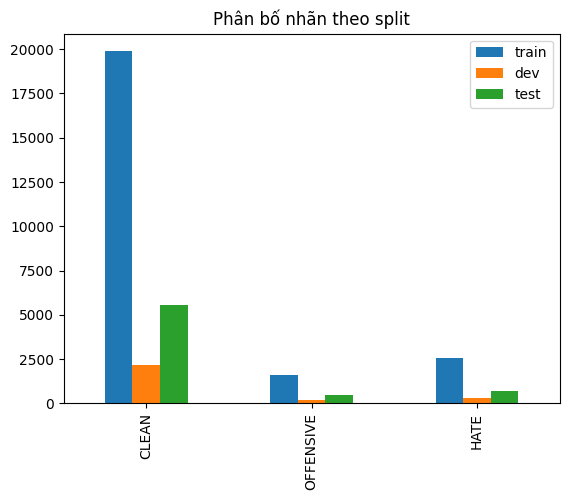

In [3]:
from vihsd.data import load_data, download_csvs
if DATA_MODE == "hf":
    from google.colab import userdata
    try:
        token = userdata.get("HF_TOKEN")
    except Exception:
        raise RuntimeError("Thêm HF_TOKEN vào Colab Secrets, cấp quyền notebook và xin quyền uitnlp/vihsd.") from None
    try:
        data_dir = download_csvs(HF_REVISION, HF_FILENAMES, token)
    finally:
        del token
    source, revision = "https://huggingface.co/datasets/uitnlp/vihsd", HF_REVISION
elif DATA_MODE == "csv":
    if SAVE_TO_DRIVE or str(CSV_DIR).startswith("/content/drive/"):
        from google.colab import drive
        drive.mount("/content/drive")
    data_dir = pathlib.Path(CSV_DIR)
    data_dir.mkdir(parents=True, exist_ok=True)
    if UPLOAD_CSV:
        print("Upload đồng thời train.csv, dev.csv và test.csv đã được cấp hợp lệ.")
        uploaded_data = files.upload()
        if set(uploaded_data) != {"train.csv", "dev.csv", "test.csv"}:
            raise ValueError("Cần đúng ba file train.csv, dev.csv, test.csv.")
        for name, payload in uploaded_data.items():
            (data_dir / name).write_bytes(payload)
        del uploaded_data
    source, revision = CSV_SOURCE, None
else:
    raise ValueError("DATA_MODE chỉ nhận csv hoặc hf.")
splits, dataset_metadata = load_data(data_dir, TEXT_COLUMN, LABEL_COLUMN, LABEL_MAPPING,
                                   MAPPING_SOURCE, source, revision, SEED, SMOKE,
                                   empty_text_policy=EMPTY_TEXT_POLICY,
                                   expected_sha256=EXPECTED_SHA256)
print("Phân bố nhãn gốc:", dataset_metadata["original_counts"])
print("Bỏ văn bản rỗng theo quy tắc chung:", dataset_metadata["dropped_empty_text"])
print("Phân bố sau lọc:", dataset_metadata["filtered_counts"])
print("Số mẫu dùng:", dataset_metadata["used_counts"])
print("Trùng giữa split (giữ nguyên split gốc, không in bình luận):", dataset_metadata["cross_split_duplicates"])
print("SHA-256:", dataset_metadata["sha256"])
import pandas as pd
pd.DataFrame(dataset_metadata["used_counts"]).plot.bar(title="Phân bố nhãn theo split")


## 4. Huấn luyện và cố định checkpoint

Fit/vocabulary/trọng số lớp chỉ trên train. Dev chọn cấu hình/checkpoint; test chỉ đánh giá cuối.


In [9]:
from vihsd.training import run_training
artifact_dir = run_training("textcnn", splits, dataset_metadata, RUN_ID, smoke=SMOKE,
                            epochs=EPOCHS, batch_size=BATCH_SIZE,
                            model_revision=PHOBERT_REVISION, code_provenance=CODE_PROVENANCE)
print("Đã xuất artifact:", artifact_dir)


Thiết bị: cuda
Epoch 1: loss=1.0318; dev macro-F1=0.5609
Epoch 2: loss=0.8007; dev macro-F1=0.5054
Epoch 3: loss=0.6635; dev macro-F1=0.5353
Epoch 4: loss=0.5716; dev macro-F1=0.5695
Epoch 5: loss=0.4784; dev macro-F1=0.6130
Epoch 6: loss=0.4115; dev macro-F1=0.6027
Epoch 7: loss=0.3509; dev macro-F1=0.6063
Epoch 8: loss=0.3068; dev macro-F1=0.6280
Epoch 9: loss=0.2761; dev macro-F1=0.6311
Epoch 10: loss=0.2502; dev macro-F1=0.6292
Epoch 11: loss=0.2056; dev macro-F1=0.6327
Epoch 12: loss=0.2060; dev macro-F1=0.6257
Epoch 13: loss=0.1966; dev macro-F1=0.6340
Epoch 14: loss=0.1703; dev macro-F1=0.6277
Epoch 15: loss=0.1575; dev macro-F1=0.6235
Epoch 16: loss=0.1485; dev macro-F1=0.6286
Epoch 17: loss=0.1387; dev macro-F1=0.6292
Epoch 18: loss=0.1347; dev macro-F1=0.6340
Epoch 19: loss=0.1279; dev macro-F1=0.6385
Epoch 20: loss=0.1269; dev macro-F1=0.6172
Epoch 21: loss=0.1171; dev macro-F1=0.6216
Epoch 22: loss=0.1159; dev macro-F1=0.6413
Epoch 23: loss=0.1158; dev macro-F1=0.6239
Epoch

## 5. Báo cáo dev và test riêng

Confusion matrix có hàng là nhãn thật, cột là nhãn dự đoán; thứ tự CLEAN/OFFENSIVE/HATE.


In [10]:
import json
metrics = json.loads((artifact_dir / "metrics.json").read_text(encoding="utf-8"))
print("Trạng thái:", metrics["run_type"])
for split in ("dev", "test"):
    print(split, "macro-F1:", metrics[split]["macro_f1"])
    display(pd.DataFrame(metrics[split]["per_class"]).T)
    display(pd.DataFrame(metrics[split]["confusion_matrix"],
                         index=["Thật CLEAN", "Thật OFFENSIVE", "Thật HATE"],
                         columns=["Đoán CLEAN", "Đoán OFFENSIVE", "Đoán HATE"]))
print("Test chỉ phục vụ báo cáo cuối, không đổi cấu hình/model theo điểm test.")


Trạng thái: full
dev macro-F1: 0.6412613998738416


,precision,recall,f1-score,support
CLEAN,0.929191,0.928767,0.928979,2190.0
OFFENSIVE,0.480000,0.339623,0.397790,212.0
HATE,0.540541,0.666667,0.597015,270.0


,Đoán CLEAN,Đoán OFFENSIVE,Đoán HATE
Thật CLEAN,2034,62,94
Thật OFFENSIVE,81,72,59
Thật HATE,74,16,180


test macro-F1: 0.6133020865022369


,precision,recall,f1-score,support
CLEAN,0.926455,0.924117,0.925284,5548.0
OFFENSIVE,0.415698,0.322072,0.362944,444.0
HATE,0.512469,0.597384,0.551678,688.0


,Đoán CLEAN,Đoán OFFENSIVE,Đoán HATE
Thật CLEAN,5127,143,278
Thật OFFENSIVE,188,143,113
Thật HATE,219,58,411


Test chỉ phục vụ báo cáo cuối, không đổi cấu hình/model theo điểm test.


## 6. Nạp lại artifact và dự đoán thử

Câu tự soạn chỉ kiểm tra luồng; không dùng làm số liệu đánh giá.


In [11]:
from vihsd.inference import Predictor
reloaded = Predictor(artifact_dir)  # CPU; chỉ đọc file đã xuất, PhoBERT local_files_only=True
for sentence in ["Cảm ơn bạn đã chia sẻ thông tin.", "Mình không đồng ý với nhận xét này.",
                 "Bài viết hôm nay rất hữu ích!"]:
    result = reloaded.predict(sentence)
    assert set(result["scores"]) == {"CLEAN", "OFFENSIVE", "HATE"}
    assert result["model_id"] == RUN_ID
    assert result["label"] in result["scores"]
    print(result)
del reloaded


{'label': 'CLEAN', 'scores': {'CLEAN': 0.9640005826950073, 'OFFENSIVE': 0.03599833324551582, 'HATE': 1.010983737614879e-06}, 'model_id': 'textcnn-full-025-001'}
{'label': 'CLEAN', 'scores': {'CLEAN': 0.9992191791534424, 'OFFENSIVE': 0.0003773785138037056, 'HATE': 0.0004034467856399715}, 'model_id': 'textcnn-full-025-001'}
{'label': 'CLEAN', 'scores': {'CLEAN': 0.9999364614486694, 'OFFENSIVE': 2.2095029805768718e-08, 'HATE': 6.349505565594882e-05}, 'model_id': 'textcnn-full-025-001'}


## 7. Xuất ZIP

Tải về hoặc lưu Drive, rồi dùng script compare_models.py tại local khi có đủ kết quả ba model.


In [12]:
# Archive root contains manifest.json; unzip it into artifacts/<model>/<run-id>/ locally.
zip_path = shutil.make_archive(str(artifact_dir.resolve()), "zip", root_dir=artifact_dir)
if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    pathlib.Path(DRIVE_OUTPUT).mkdir(parents=True, exist_ok=True)
    destination = pathlib.Path(DRIVE_OUTPUT) / pathlib.Path(zip_path).name
    shutil.copyfile(zip_path, destination)
    print("Đã lưu ZIP vào Drive:", destination)
if DOWNLOAD_ZIP:
    files.download(zip_path)
print("Không commit ZIP/artifact/CSV/token vào Git.")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Không commit ZIP/artifact/CSV/token vào Git.
